# Numerical Exercises 4
## Exercise 4.1
In Statistical Mechanics the Maxwell–Boltzmann distribution (<a href="https://en.wikipedia.org/wiki/Maxwell%E2%80%93Boltzmann_distribution" target="_blank">Link Wikipedia</a>) is a probability distribution used for describing particle speeds in idealized gases. However, rarefied gases at ordinary temperatures behave very nearly like an ideal gas and the Maxwell–Boltzmann speed distribution is an excellent approximation for such gases. For a 3D system its formula is:
$$p(v,T) = \left( \frac{m}{2\pi k_B T} \right)^{3/2} 4\pi v^2 e^{-\frac{m v^2}{2 k_B T}}$$

By using LJ reduced units (Lenght: $\sigma$; Energy: $\epsilon$; Mass: the mass, $m$, of the particles; Temperature: $\epsilon/k_B$; velocity: $\sqrt{\epsilon/m}$) its form becomes:
$$p(v^*,T^*) = \frac{1}{(2\pi T^*)^{3/2}} 4\pi (v^*)^2 e^{-\frac{(v^*)^2}{2 T^*}}$$

The NSL_SIMULATOR code already computes the total (internal) energy per particle, $E/N$, the potential energy per particle, $U/N$, the kinetic energy per particle, $K/N$, the temperature, $T$, and the pressure, $P$.

<span style="color:red">Include the calculation of the Maxwell–Boltzmann distribution, $p(v^*,T^*)$, inside your Molecular Dynamics code by using data blocking to obtain single block averages, progressive average values and progressive uncertainties for $p(v^*,T^*)$.</span>

Remember that, the Maxwell–Boltzmann distribution, $p(v^*,T^*)$, can be approximately computed as a **normalized histogram** on an appropriate interval $\left[ 0, v_{max}\right]$ and chosing the number of bins into which you want to divide this interval.

### **Solution**
### Microcanonical Ensemble and Molecular Dynamics

In this exercise, a classical many-body system of interacting particles via the Lennard-Jones potential is simulated within the microcanonical ensemble ($NVE$), characterized by a constant number of particles $N$, volume $V$, and total energy $E$.

To investigate bulk properties and eliminate finite-size boundary effects caused by the reduced number of particles compared to the thermodynamic limit ($N \sim 10^{23}$), Periodic Boundary Conditions (PBC) are applied to a cubic box of reduced volume $V^*$. Furthermore, the long-range tail of the potential is truncated beyond a cut-off radius $r_c$ to reduce computational cost.

The trajectory in phase space is computed by integrating the equations of motion using the Verlet algorithm:
$$\vec{r}(t + \delta t) \simeq 2\vec{r}(t) - \vec{r}(t - \delta t) + \vec{a}(t)\delta t^2$$
This symplectic, time-reversible scheme does not require velocities to propagate positions, but they can be evaluated via the central difference formula with an error of order $O(\delta t^2)$:
$$\vec{v}(t) = \frac{\vec{r}(t + \delta t) - \vec{r}(t - \delta t)}{2\delta t}$$

### Maxwell–Boltzmann Distribution

At thermodynamic equilibrium, the probability distribution of particle speeds $v$ in a three-dimensional ideal or rarefied gas is given by the Maxwell–Boltzmann distribution:
$$p(v, T) = \left(\frac{m}{2\pi k_B T}\right)^{3/2} 4\pi v^2 \exp\left(-\frac{m v^2}{2 k_B T}\right)$$
Using Lennard-Jones reduced units (length $\sigma$, energy $\epsilon$, mass $m$, reduced temperature $T^* = k_B T / \epsilon$, and reduced velocity $v^* = v / \sqrt{\epsilon / m}$), the probability density function simplifies to:
$$p(v^*, T^*) = \frac{1}{(2\pi T^*)^{3/2}} 4\pi (v^*)^2 \exp\left(-\frac{(v^*)^2}{2 T^*}\right)$$

### Implementation and Data Blocking

To compute the Maxwell–Boltzmann distribution $p(v^*)$ within the molecular dynamics framework, the velocity interval $[0, v_{\max}]$ is discretized into $N_{\text{bins}} = 50$ bins of uniform width $\Delta v = v_{\max} / N_{\text{bins}}$.

The calculation is integrated into the simulation through the following hierarchical procedure:

* **Step-by-step measurement** `measure()`: At each integration time step, the instantaneous velocity vector $\vec{v}_i$ is obtained for every particle $i = 1, \dots, N$. The speed modulus $v_i^* = \vert{}\vec{v}_i^*\vert{}$ is computed, and the corresponding bin index is identified as $\text{bin} = \lfloor v_i^* / \Delta v \rfloor$. If the speed falls within $[0, v_{\max}]$, the counter for that specific bin in the block accumulator `_block_av` is incremented by 1.
* **Block normalization** `averages()`: At the end of each block of $N_{\text{steps}}$, the accumulated counts in each bin are normalized by dividing by the total number of steps, the total number of particles $N$, and the bin width $\Delta v$:
  $$p_{\text{block}}(v_k^*) = \frac{N_k}{N_{\text{steps}} \cdot N \cdot \Delta v}$$
  This conversion ensures that the histogram represents a proper probability density function satisfying $\int_0^{\infty} p(v^*) \, dv^* \simeq \sum_k p_{\text{block}}(v_k^*) \Delta v = 1$.
* **Data blocking across blocks:** Each velocity bin is treated as an independent statistical property. Progressive averages and their corresponding statistical uncertainties are evaluated block by block via the standard data blocking technique, yielding the final empirical distribution with well-defined error bars to be compared against the analytical Maxwell–Boltzmann curve.

To monitor the equilibration process, I tracked the evolution of the **instantaneous temperature** $T$, which directly reflects the kinetic energy per degree of freedom:
As shown in the equilibration plot, the initial temperature drift quickly levels off, entering a stationary regime characterized by typical equilibrium fluctuations around a constant mean value.

Based on this observed plateau, I implemented a dedicated equilibration routine within the simulation code, choosing 5000 steps:

```cpp
void System::equilibration(int nsteps) {
  for (int i = 0; i < nsteps; i++) {
    this->step();
  }
}
```
To validate the implementation of $p(v^*)$, the normalized velocity histogram obtained from the simulation was directly compared with the theoretical Maxwell–Boltzmann distribution. The analytical curve was evaluated using the final mean temperature measured during the production run.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

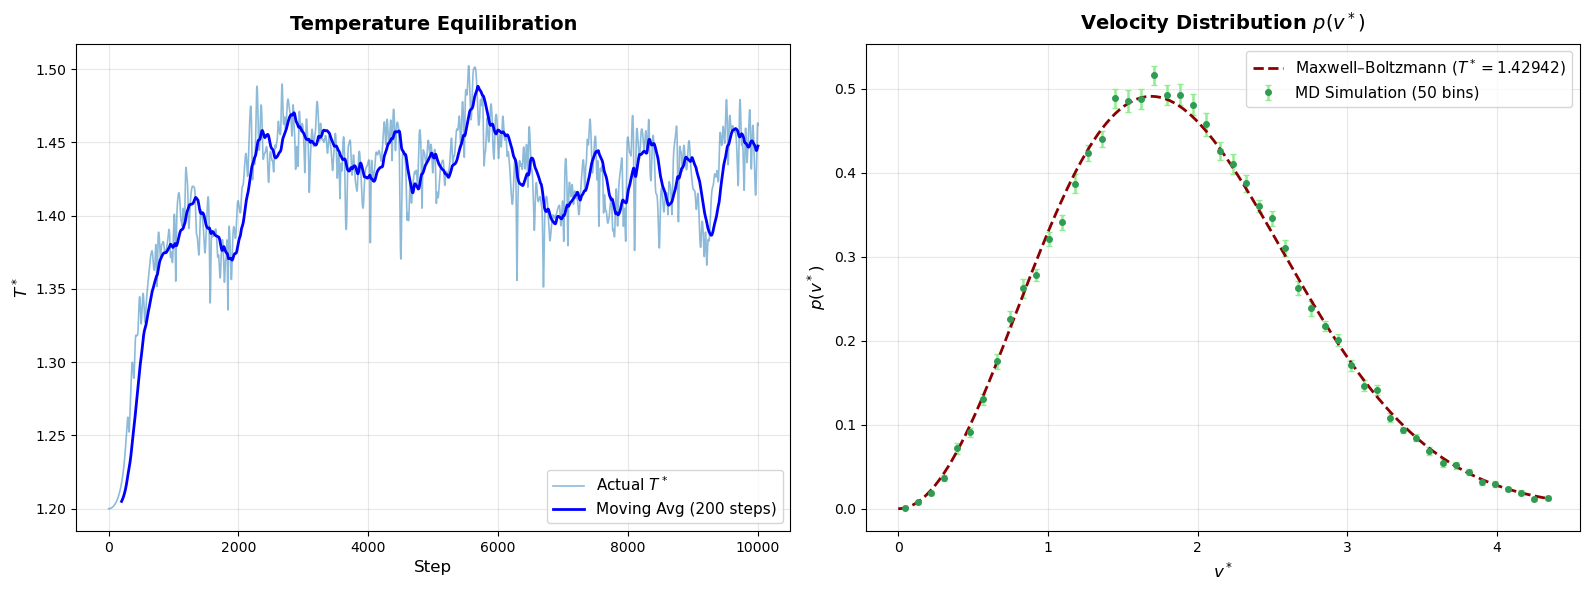

In [10]:
eq_steps, actual_temp = np.loadtxt("4.1/OUTPUT/temperature_EQ.dat", usecols=(0, 1), unpack=True)
bin_centers, p_val, p_err = np.loadtxt("4.1/OUTPUT/POFV/pofv_40.dat", usecols=(0, 2, 3), unpack=True)
T_star = 1.42942
v_theory = np.linspace(0, bin_centers.max(), 300)
p_theory = (1.0 / (2.0 * np.pi * T_star)**1.5) * 4.0 * np.pi * (v_theory**2) * np.exp(- (v_theory**2) / (2.0 * T_star))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(eq_steps, actual_temp, color="#1f77b4", alpha=0.5, linewidth=1.2, label=r"Actual $T^*$")

if len(eq_steps) >= 200: 
    window = 200
    moving_avg = np.convolve(actual_temp, np.ones(window)/window, mode='valid')
    ax1.plot(eq_steps[window-1:], moving_avg, color="blue", linewidth=2.0, label=f"Moving Avg ({window} steps)")

ax1.set_title("Temperature Equilibration", fontsize=14, fontweight="bold", pad=10)
ax1.set_xlabel("Step", fontsize=12)
ax1.set_ylabel(r"$T^*$", fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=11)

ax2.errorbar(bin_centers, p_val, yerr=p_err, fmt='o', markersize=4, color="#319B54", ecolor='lightgreen', elinewidth=1.8, capsize=2, label='MD Simulation (50 bins)')

ax2.plot(v_theory, p_theory, color='darkred', linestyle='--', linewidth=2, label=f'Maxwell–Boltzmann ($T^*={T_star}$)')

ax2.set_title(r"Velocity Distribution $p(v^*)$", fontsize=14, fontweight="bold", pad=10)
ax2.set_xlabel(r"$v^*$", fontsize=12)
ax2.set_ylabel(r"$p(v^*)$", fontsize=12)
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()

## Exercise 04.2

By means of your upgraded code, <span style="color:red">perform MD simulations via a Lennard-Jones model</span> ( e.g. Argon parameters: $\sigma = 0.34$ nm, $\epsilon/k_B = 120$ K, $m=39.948$ amu) in the following conditions:
- gas phase: $\rho^\star = 0.05$, $T^\star \sim  2.0$ (cut-off radius: $r_c = 5.0$)

starting from a <span style="color:red">**very low entropic** initial configuration</span>:
1. initial **particle positions**: <span style="color:red">fcc crystal occupying half of the simulation box in each dimension</span>
2. initial **velocity distribution**: <span style="color:red">$p_\delta(v^*,T^*) = \delta\left( v^* - v_{T^*}\right)$</span> where $v_{T^*}$ is suitably connected to $T^*$. For example, this condition could be obtained by imposing that every particle has an initial velocity $\pm v_{T^*}$ for **only one** of its velocity components: $v_x$, $v_y$, $v_z$.

The goal is to show that, by evolving such initial condition via a Molecular Dynamics simulation, the velocity distribution tends to approximate the Maxwell–Boltzmann distribution.

- **Produce some pictures that show this convergence**
- The evolution of the system moves towards the increasing of entropy (more homeogeneous configuration of particles)? What would you find by changing the direction of time? Comment on these aspects in your jupyter-notebook

**Note that** the MD simulation will conserve the total energy; thus the kinetic energy and the temperature are not constant of motion ... the comparison should be done with $p(v^*,T^*_{\rm eff})$ where $T^*_{\rm eff}$ is the effective temperature obtained once the system has been equilibrated.

### **Solution**
At the initial step (Block 0), the velocity distribution is initialized to approximate a Dirac $\delta$-function. However, the resulting histogram exhibits a slight broadening across adjacent bins rather than a mathematically perfect single vertical line. This is an expected finite-size effect caused by the subtraction of the Center of Mass (CM) velocity ($\vec{v}_{\text{CM}}$). Although this subtraction introduces a slight spread in the initial velocity modules, it is **strictly mandatory in Molecular Dynamics**.

Using progressive averages is physically meaningless when studying a transient, out-of-equilibrium process. A cumulative average would integrate over time, improperly mixing the initial non-equilibrium configurations with the later thermalized states, thereby completely obscuring the temporal evolution of the gas.
### Simulation Parameters
The Molecular Dynamics (MD) simulation was performed using **50 blocks** consisting of **100 steps** each. In the context of the data analysis, **"Block 0"** denotes the exact initial configuration at the very first step ($t=0$) prior to any time integration, and does not represent a standard statistical block.

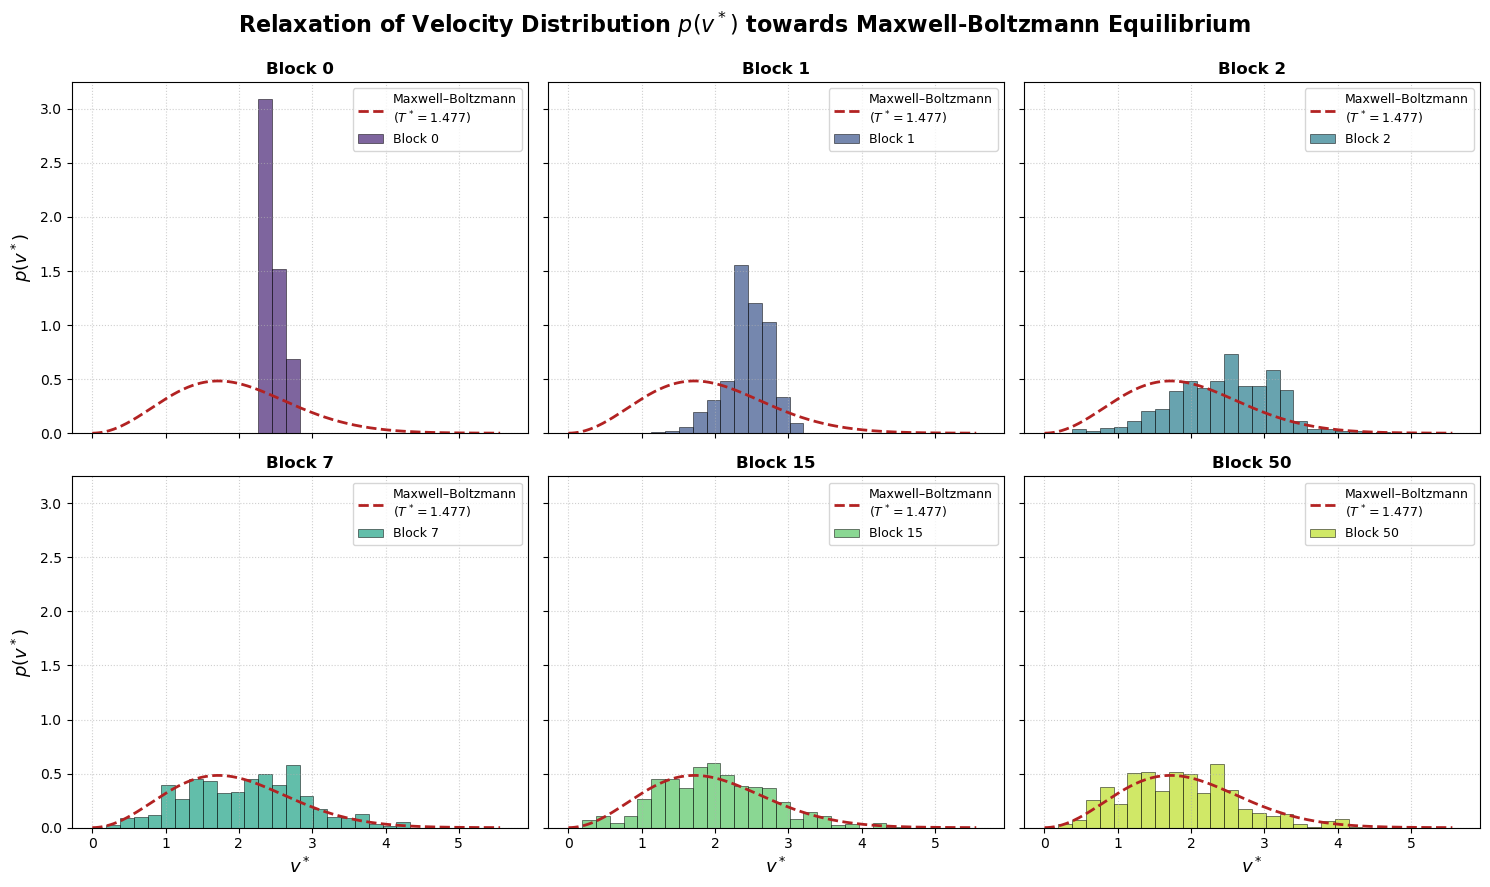

In [ ]:
base_path = "4.2/OUTPUT/POFV/pofv_" 
blocks_to_plot = [0, 1, 2, 7, 15, 50]

temp_data = np.loadtxt("4.2/OUTPUT/temperature.dat")
T_star = temp_data[-1, 2] 
def maxwell_boltzmann(v, T):
    return (2.0 / np.pi)**0.5 * (1.0 / T)**1.5 * (v**2) * np.exp(- (v**2) / (2.0 * T))
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 9), sharex=True, sharey=True)
axes = axes.flatten()

colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(blocks_to_plot)))

for idx, (blk, ax, color) in enumerate(zip(blocks_to_plot, axes, colors)):
    filepath = f"{base_path}{blk}.dat"
    try:
        v, p_blk = np.loadtxt(filepath, usecols=(0, 1), unpack=True)
        bin_width = v[1] - v[0] if len(v) > 1 else 0.1
        ax.bar(v, p_blk, width=bin_width, color=color, alpha=0.7, edgecolor='black', linewidth=0.5, label=f"Block {blk}")
        

        v_dense = np.linspace(0.0, v[-1], 500)
        p_theory = maxwell_boltzmann(v_dense, T_star)
        ax.plot(v_dense, p_theory, color='firebrick', linestyle='--', linewidth=2, 
                label=f"Maxwell–Boltzmann\n($T^* = {T_star:.3f}$)")
        ax.set_title(f"Block {blk}", fontsize=12, fontweight='bold')
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(fontsize=9, loc='upper right')
        
    except FileNotFoundError:
        print(f"File non trovato: {filepath}")
        ax.text(0.5, 0.5, 'File Not Found', horizontalalignment='center', verticalalignment='center', transform=ax.transAxes)

for ax in axes[-3:]:
    ax.set_xlabel(r"$v^*$", fontsize=13)
for ax in axes[[0, 3]]:
    ax.set_ylabel(r"$p(v^*)$", fontsize=13)

fig.suptitle(r"Relaxation of Velocity Distribution $p(v^*)$ towards Maxwell-Boltzmann Equilibrium", 
             fontsize=16, fontweight='bold', y=0.98)

plt.tight_layout()
plt.subplots_adjust(top=0.90)

plt.savefig("pofv_multiplot_evolution.png", dpi=300)
plt.show()

### Visualizing the System Evolution

Below is an animation of the molecular dynamics trajectory exported via OVITO. It illustrates the real-time melting and spatial expansion of the system, starting from the ordered initial FCC lattice and progressing toward the disordered fluid state during the equilibration phase.

<img src="4.2/OUTPUT/simulation.gif" width="600">

### Thermodynamic and Statistical Equilibrium
The macroscopic equilibration of the system is confirmed by monitoring the energy and temperature trajectories over time. As shown in the following equilibration plots, the initial transient phase dissipates, and the kinetic energy (along with the temperature $T$) begins to stably fluctuate around a mean effective value $T^*_{\text{eff}}$ well before the final sampled block. 

Consequently, the velocity distribution extracted at Block 50 (step 5000) represents a system that has already reached full thermodynamic equilibrium. This stability justifies the assumption that the relaxation process is complete, allowing the theoretical Maxwell-Boltzmann curve, calculated using the actual $T^*_{\text{eff}}$ of that specific block, to be used to fit our data.

The following right plot shows conservation of total energy in Verlet algorithm.

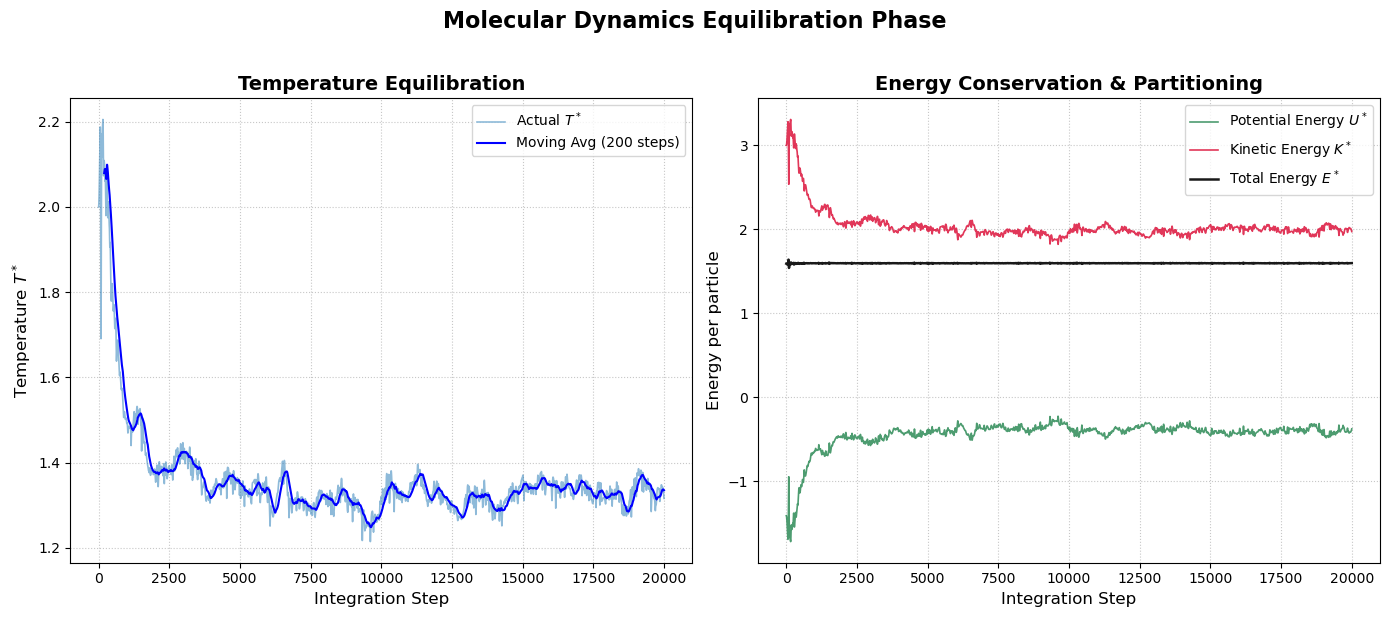

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

base_path = "4.2/OUTPUT/"

eq_steps, actual_temp = np.loadtxt(base_path + "temperature_equil.dat", usecols=(0, 1), unpack=True)
_, kin = np.loadtxt(base_path + "kinetic_energy.dat", usecols=(0, 1), unpack=True)
_, pot = np.loadtxt(base_path + "potential_energy.dat", us
                    ecols=(0, 1), unpack=True)
_, tot = np.loadtxt(base_path + "total_energy.dat", usecols=(0, 1), unpack=True)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

ax1.plot(eq_steps, actual_temp, color="#1f77b4", alpha=0.5, linewidth=1.2, label=r"Actual $T^*$")

if len(eq_steps) >= 200: 
    window = 200
    moving_avg = np.convolve(actual_temp, np.ones(window)/window, mode='valid')
    ax1.plot(eq_steps[window-1:], moving_avg, color="blue", linewidth=1.5, label=f"Moving Avg ({window} steps)")

ax1.set_title("Temperature Equilibration", fontsize=14, fontweight='bold')
ax1.set_xlabel("Integration Step", fontsize=12)
ax1.set_ylabel(r"Temperature $T^*$", fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.legend(loc='best', frameon=True)

ax2.plot(eq_steps, pot, color='seagreen', alpha=0.85, linewidth=1.2, label="Potential Energy $U^*$")
ax2.plot(eq_steps, kin, color='crimson', alpha=0.85, linewidth=1.2, label="Kinetic Energy $K^*$")
ax2.plot(eq_steps, tot, color='black', alpha=0.9, linewidth=1.8, label="Total Energy $E^*$")

ax2.set_title("Energy Conservation & Partitioning", fontsize=14, fontweight='bold')
ax2.set_xlabel("Integration Step", fontsize=12)
ax2.set_ylabel(r"Energy per particle", fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.7)
ax2.legend(loc='best', frameon=True)

fig.suptitle("Molecular Dynamics Equilibration Phase", fontsize=16, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig("equilibration_full_multiplot.png", dpi=300, bbox_inches='tight')
plt.show()

## Exercise 04.3

Starting from the **final states** of two MD simulations of the system in Exercise 04.2, one with about $5\times 10^3$ time-steps the other with about $5\times 10^4$ time-steps, by changing the direction of time (e.g. by inverting the final velocities, i.e. ... ), try to return back to the very low entropic initial configuration of Exercise 04.2. Is this possible? (for example, one can monitor the behavior of the average **potential energy** and the average **temperature** in **each block** as a function of time going **in both directions**. Show some picture and comment on what you find in your jupyter-notebook.

### **Solution** 

To set up this experiment, the forward simulation was initialized from a highly ordered, low-entropy **FCC crystal lattice**, with initial velocities generated from a **delta distribution**. <br>
Since the **Verlet integration algorithm** is strictly time-reversible and computes the system's evolution using only the spatial coordinates at $t$ and $t - \delta t$ (rather than explicit velocities), we can easily reverse the direction of time. This is achieved by simply **swapping the final configuration files** (`config.xyz` and `conf-1.xyz`) before restarting the backward simulation.

Plots of forward and backward simulation are now displayed, 5000 and 50000 steps.

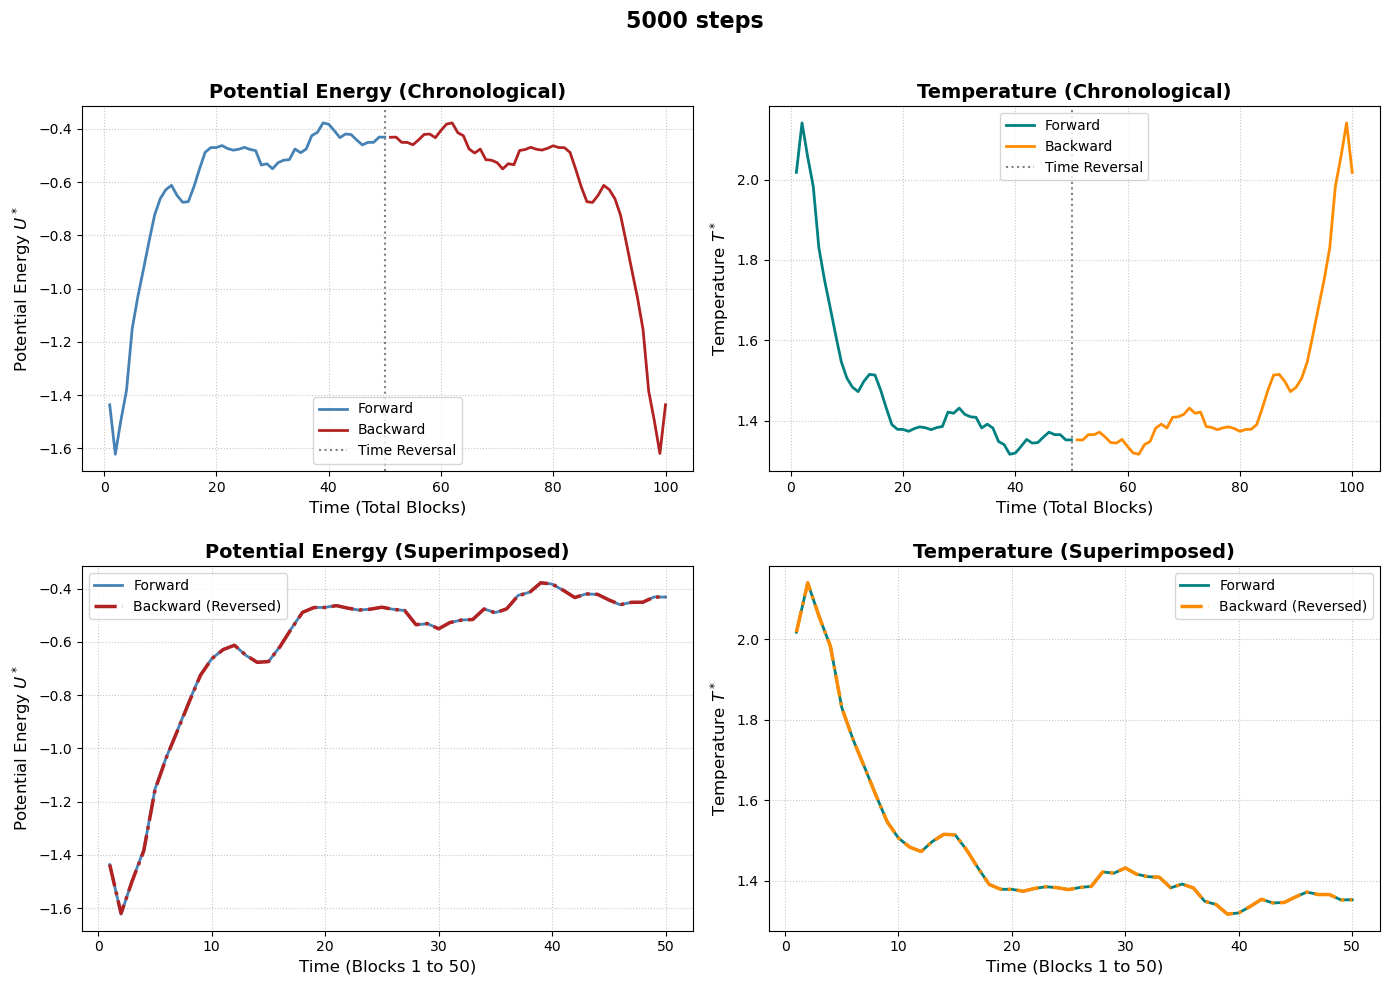

In [76]:
file_pe_f = "4.3/OUTPUT/plot/shortf_penergy.dat"  
file_pe_b = "4.3/OUTPUT/plot/shortb_penergy.dat"  
file_t_f  = "4.3/OUTPUT/plot/shortf_temperature.dat"  
file_t_b  = "4.3/OUTPUT/plot/shortb_temperature.dat"  

c_pe_f = "steelblue"     # Potential Energy Forward
c_pe_b = "firebrick"     # Potential Energy Backward
c_t_f  = "teal"          # Temperature Forward
c_t_b  = "darkorange"    # Temperature Backward

blk_pe_f, pe_val_f = np.loadtxt(file_pe_f, usecols=(0, 1), unpack=True)
blk_pe_b, pe_val_b = np.loadtxt(file_pe_b, usecols=(0, 1), unpack=True)
blk_t_f, t_val_f = np.loadtxt(file_t_f, usecols=(0, 1), unpack=True)
blk_t_b, t_val_b = np.loadtxt(file_t_b, usecols=(0, 1), unpack=True)

blk_pe_b_shifted = blk_pe_b + blk_pe_f[-1]
blk_t_b_shifted = blk_t_b + blk_t_f[-1]

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))

ax1.plot(blk_pe_f, pe_val_f, color=c_pe_f, label='Forward', linestyle='-', linewidth=2)
ax1.plot(blk_pe_b_shifted, pe_val_b, color=c_pe_b, label='Backward', linestyle='-', linewidth=2)

ax1.axvline(x=blk_pe_f[-1], color='gray', linestyle=':', label='Time Reversal')
ax1.set_title("Potential Energy (Chronological)", fontsize=14, fontweight='bold')
ax1.set_xlabel("Time (Total Blocks)", fontsize=12)
ax1.set_ylabel(r"Potential Energy $U^*$", fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.legend(loc='best', frameon=True, fontsize=10)

ax2.plot(blk_t_f, t_val_f, color=c_t_f, label='Forward', linestyle='-', linewidth=2)
ax2.plot(blk_t_b_shifted, t_val_b, color=c_t_b, label='Backward', linestyle='-', linewidth=2)

ax2.axvline(x=blk_t_f[-1], color='gray', linestyle=':', label='Time Reversal')
ax2.set_title("Temperature (Chronological)", fontsize=14, fontweight='bold')
ax2.set_xlabel("Time (Total Blocks)", fontsize=12)
ax2.set_ylabel(r"Temperature $T^*$", fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.7)
ax2.legend(loc='best', frameon=True, fontsize=10)

ax3.plot(blk_pe_f, pe_val_f, color=c_pe_f, label='Forward', linestyle='-', linewidth=2)
ax3.plot(blk_pe_f, pe_val_b[::-1], color=c_pe_b, label='Backward (Reversed)', linestyle='-.', linewidth=2.5)

ax3.set_title("Potential Energy (Superimposed)", fontsize=14, fontweight='bold')
ax3.set_xlabel("Time (Blocks 1 to 50)", fontsize=12)
ax3.set_ylabel(r"Potential Energy $U^*$", fontsize=12)
ax3.grid(True, linestyle=':', alpha=0.7)
ax3.legend(loc='best', frameon=True, fontsize=10)

ax4.plot(blk_t_f, t_val_f, color=c_t_f, label='Forward', linestyle='-', linewidth=2)
ax4.plot(blk_t_f, t_val_b[::-1], color=c_t_b, label='Backward (Reversed)', linestyle='-.', linewidth=2.5)

ax4.set_title("Temperature (Superimposed)", fontsize=14, fontweight='bold')
ax4.set_xlabel("Time (Blocks 1 to 50)", fontsize=12)
ax4.set_ylabel(r"Temperature $T^*$", fontsize=12)
ax4.grid(True, linestyle=':', alpha=0.7)
ax4.legend(loc='best', frameon=True, fontsize=10)

fig.suptitle("5000 steps", fontsize=16, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=2.0)
plt.show()

The simulation consists of two sequential phases of 50 blocks each (5000 steps forward, followed by 5000 steps in reverse after inverting time).
Because the Verlet integration algorithm is time-reversible, the backward run (blocks 51 to 100) retraces the forward trajectory in a specular way, showing no discontinuity at the inversion point.
Over a short run of 5000 steps, numerical round-off errors remain negligible, allowing the system to retrace its path back to the starting state and recover the initial energy and temperature values.

Now we proceed with 50000 steps, in order to find out if irreversibility of this simulation is manteined in bigger simulations.

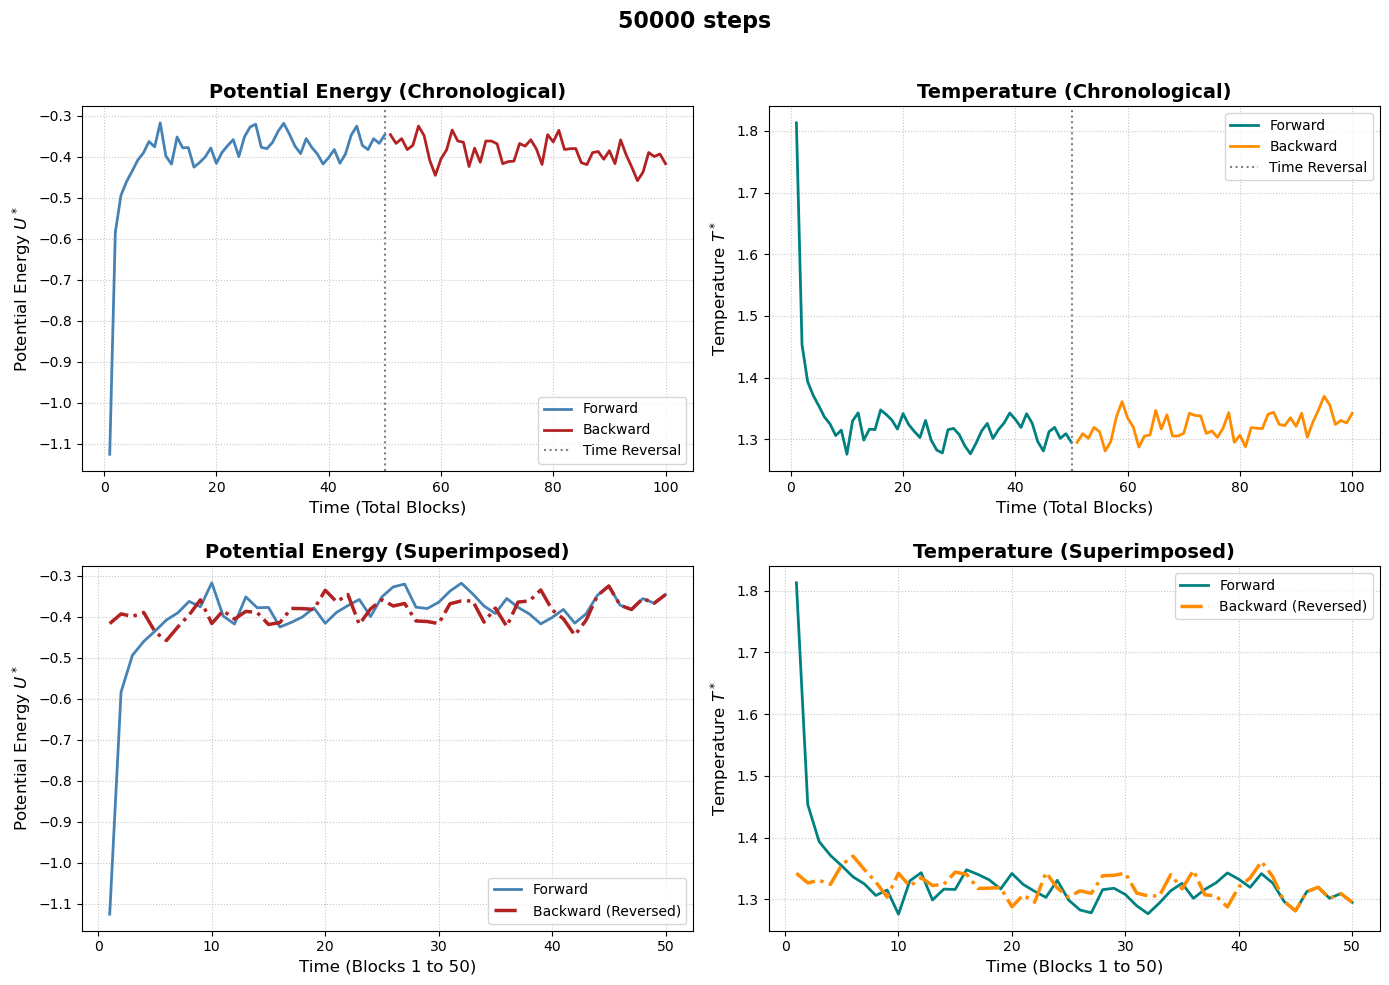

In [80]:
file_pe_f = "4.3/OUTPUT/plot/longf_penergy.dat"  
file_pe_b = "4.3/OUTPUT/plot/longb_penergy.dat"  
file_t_f  = "4.3/OUTPUT/plot/longf_temperature.dat"  
file_t_b  = "4.3/OUTPUT/plot/longb_temperature.dat"  

c_pe_f = "steelblue"     # Potential Energy Forward
c_pe_b = "firebrick"     # Potential Energy Backward
c_t_f  = "teal"          # Temperature Forward
c_t_b  = "darkorange"    # Temperature Backward

blk_pe_f, pe_val_f = np.loadtxt(file_pe_f, usecols=(0, 1), unpack=True)
blk_pe_b, pe_val_b = np.loadtxt(file_pe_b, usecols=(0, 1), unpack=True)
blk_t_f, t_val_f = np.loadtxt(file_t_f, usecols=(0, 1), unpack=True)
blk_t_b, t_val_b = np.loadtxt(file_t_b, usecols=(0, 1), unpack=True)

blk_pe_b_shifted = blk_pe_b + blk_pe_f[-1]
blk_t_b_shifted = blk_t_b + blk_t_f[-1]

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))

ax1.plot(blk_pe_f, pe_val_f, color=c_pe_f, label='Forward', linestyle='-', linewidth=2)
ax1.plot(blk_pe_b_shifted, pe_val_b, color=c_pe_b, label='Backward', linestyle='-', linewidth=2)

ax1.axvline(x=blk_pe_f[-1], color='gray', linestyle=':', label='Time Reversal')
ax1.set_title("Potential Energy (Chronological)", fontsize=14, fontweight='bold')
ax1.set_xlabel("Time (Total Blocks)", fontsize=12)
ax1.set_ylabel(r"Potential Energy $U^*$", fontsize=12)
ax1.grid(True, linestyle=':', alpha=0.7)
ax1.legend(loc='best', frameon=True, fontsize=10)

ax2.plot(blk_t_f, t_val_f, color=c_t_f, label='Forward', linestyle='-', linewidth=2)
ax2.plot(blk_t_b_shifted, t_val_b, color=c_t_b, label='Backward', linestyle='-', linewidth=2)

ax2.axvline(x=blk_t_f[-1], color='gray', linestyle=':', label='Time Reversal')
ax2.set_title("Temperature (Chronological)", fontsize=14, fontweight='bold')
ax2.set_xlabel("Time (Total Blocks)", fontsize=12)
ax2.set_ylabel(r"Temperature $T^*$", fontsize=12)
ax2.grid(True, linestyle=':', alpha=0.7)
ax2.legend(loc='best', frameon=True, fontsize=10)

ax3.plot(blk_pe_f, pe_val_f, color=c_pe_f, label='Forward', linestyle='-', linewidth=2)
ax3.plot(blk_pe_f, pe_val_b[::-1], color=c_pe_b, label='Backward (Reversed)', linestyle='-.', linewidth=2.5)

ax3.set_title("Potential Energy (Superimposed)", fontsize=14, fontweight='bold')
ax3.set_xlabel("Time (Blocks 1 to 50)", fontsize=12)
ax3.set_ylabel(r"Potential Energy $U^*$", fontsize=12)
ax3.grid(True, linestyle=':', alpha=0.7)
ax3.legend(loc='best', frameon=True, fontsize=10)

ax4.plot(blk_t_f, t_val_f, color=c_t_f, label='Forward', linestyle='-', linewidth=2)
ax4.plot(blk_t_f, t_val_b[::-1], color=c_t_b, label='Backward (Reversed)', linestyle='-.', linewidth=2.5)

ax4.set_title("Temperature (Superimposed)", fontsize=14, fontweight='bold')
ax4.set_xlabel("Time (Blocks 1 to 50)", fontsize=12)
ax4.set_ylabel(r"Temperature $T^*$", fontsize=12)
ax4.grid(True, linestyle=':', alpha=0.7)
ax4.legend(loc='best', frameon=True, fontsize=10)

fig.suptitle("50000 steps", fontsize=16, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=2.0)
plt.show()

The plots clearly illustrate the effect of thermodynamic instability on the system's reversibility. In the upper chronological plots, the backward trajectory connects continuously to the end of the forward run, confirming the correct execution of the time inversion at block 50. However, the lower superimposed graphs reveal the true backward dynamics: the forward and reversed curves coincide perfectly only for the very first moments after the inversion, before **diverging significantly** as time flows backward. This separation demonstrates that the inevitable numerical amplification of **round-off errors** rapidly destroys the ideal trajectory, preventing the system from retracing its equilibration phase and returning to the exact initial configuration.